<a href="https://colab.research.google.com/github/maanavj18/Lambda-AI-Powered-Text-Intelligence-Platform/blob/main/notebooks/1_data_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
#mile stone 1
import kagglehub, os
path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")
print(path, os.listdir(path))
seed = 45

Using Colab cache for faster access to the 'amazon-fine-food-reviews' dataset.
/kaggle/input/amazon-fine-food-reviews ['hashes.txt', 'Reviews.csv', 'database.sqlite']


In [30]:
import pandas as pd
df_full = pd.read_csv(os.path.join(path, "Reviews.csv"))
print(df_full.shape)
df_full.head()

(568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [31]:
df = df_full.sample(50000, random_state=42).reset_index(drop=True)
df.to_csv("sample_50k.csv", index=False)
print(df.shape)

(50000, 10)


In [32]:
sample = pd.read_csv("sample_50k.csv")
print("Missing values:\n", sample.isna().sum())
print("Duplicates:", sample.duplicated(['UserId', 'Time', 'Text']).sum())
print(sample.Score.value_counts().sort_index())

Missing values:
 Id                        0
ProductId                 0
UserId                    0
ProfileName               0
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   1
Text                      0
dtype: int64
Duplicates: 3668
Score
1     4528
2     2576
3     3791
4     7008
5    32097
Name: count, dtype: int64


In [33]:
df = df[df.Score != 3].copy()
df['label'] = (df.Score >= 4).map({True: 'positive', False: 'negative'})
words = df.Text.str.split().str.len()

print("Rows after dropping 3s:", len(df))
print(df.label.value_counts())
print(df.label.value_counts(normalize=True).round(3))
print("Avg words:", round(words.mean(), 1), "| Median:", words.median())

Rows after dropping 3s: 46209
label
positive    39105
negative     7104
Name: count, dtype: int64
label
positive    0.846
negative    0.154
Name: proportion, dtype: float64
Avg words: 78.9 | Median: 55.0


In [34]:
#### milestone 2
import pandas as pd, kagglehub, os
path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")
df = pd.read_csv(os.path.join(path, "Reviews.csv")).sample(50000, random_state=42).reset_index(drop=True)
df.to_csv("sample_50k.csv", index=False)

df = df[df.Score != 3].drop_duplicates(['UserId', 'Time', 'Text']).copy()
df['label'] = (df.Score >= 4).astype(int)
df['Summary'] = df['Summary'].fillna('')
df['clean'] = (df.Summary + ' ' + df.Text).str.replace(r'<.*?>', ' ', regex=True)
print(len(df))

Using Colab cache for faster access to the 'amazon-fine-food-reviews' dataset.
42795


In [35]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, test_size=0.2, stratify=df.label, random_state=42)
train.to_csv("train.csv", index=False)
test.to_csv("test.csv", index=False)
print(len(train), len(test))
print(round(train.label.mean(), 3), round(test.label.mean(), 3))

34236 8559
0.847 0.847


In [36]:
from sklearn.feature_extraction.text import CountVectorizer
bow = CountVectorizer(min_df=5)
X_train = bow.fit_transform(train.clean)
X_test = bow.transform(test.clean)
print("Vocab size:", len(bow.vocabulary_))
print("Shape:", X_train.shape)

Vocab size: 11553
Shape: (34236, 11553)


In [37]:
from sklearn.linear_model import LogisticRegression
import numpy as np
lr = LogisticRegression(max_iter=1000).fit(X_train, train.label)
words = np.array(bow.get_feature_names_out())
order = lr.coef_[0].argsort()
print("Top negative:", list(words[order[:10]]))
print("Top positive:", list(words[order[-10:]]))

Top negative: ['disappointing', 'terrible', 'horrible', 'multigrain', 'yuck', 'beware', 'worst', 'rise', 'feedback', 'awful']
Top positive: ['bargain', 'yum', 'addictive', 'awesome', 'perfect', 'yummy', 'satisfied', 'delicious', 'excellent', 'fantastic']


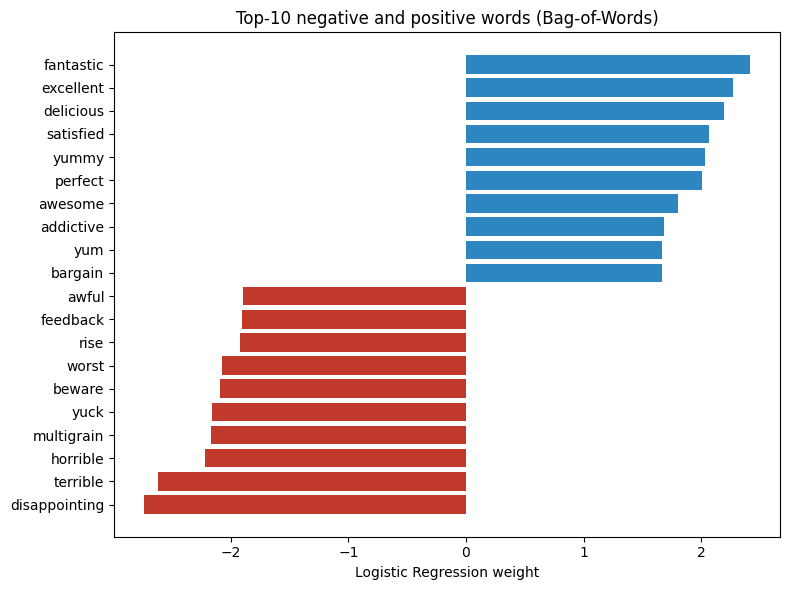

In [38]:
# Chart the 10 most negative and 10 most positive bag-of-words weights.
import matplotlib.pyplot as plt
idx = np.concatenate([order[:10], order[-10:]])
plt.figure(figsize=(8, 6))
plt.barh(words[idx], lr.coef_[0][idx], color=['#c0392b']*10 + ['#2e86c1']*10)
plt.xlabel("Logistic Regression weight")
plt.title("Top-10 negative and positive words (Bag-of-Words)")
plt.tight_layout()
plt.savefig("bow_top_words.png", dpi=150)
plt.show()

In [39]:
# Fit Multinomial Naive Bayes on the bag-of-words counts, and build a
# majority-class baseline that always predicts the most common training
# label.
import numpy as np
from sklearn.naive_bayes import MultinomialNB

y_train = train["label"]
y_test = test["label"]

# alpha=1.0 is Laplace smoothing, so a word never seen for a class
# does not wipe out that class's probability.
nb = MultinomialNB(alpha=1.0)
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

majority_label = y_train.value_counts().idxmax()
majority_pred = np.full(len(y_test), majority_label)

print("Majority label:", majority_label)
print("Test reviews:", len(y_test))

Majority label: 1
Test reviews: 8559


In [40]:
# Save the fitted vectorizer and classifier together for app inference.
from pathlib import Path
from joblib import dump
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("vectorizer", bow),
    ("classifier", lr),  # Replace lr with nb to deploy Naive Bayes.
])

# Run from the repository root; copy this file to models/ if using Colab.
Path("models").mkdir(exist_ok=True)
dump(model, "models/sentiment.joblib")


['models/sentiment.joblib']

In [41]:
# Score both models on the held-out test set. Macro precision, recall, and F1
# weight the negative and positive classes equally.
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
)

predictions = {
    "Majority baseline": majority_pred,
    "Multinomial Naive Bayes": nb_pred,
}

rows = []
for name, pred in predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, labels=[0, 1], average="macro", zero_division=0
    )
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro precision": precision,
        "Macro recall": recall,
        "Macro F1": f1,
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

print(classification_report(
    y_test, nb_pred,
    labels=[0, 1], target_names=["Negative", "Positive"], zero_division=0
))

,Accuracy,Macro precision,Macro recall,Macro F1
Model,,,,
Majority baseline,0.8467,0.4234,0.5000,0.4585
Multinomial Naive Bayes,0.9168,0.8335,0.8604,0.8460


              precision    recall  f1-score   support

    Negative       0.71      0.78      0.74      1312
    Positive       0.96      0.94      0.95      7247

    accuracy                           0.92      8559
   macro avg       0.83      0.86      0.85      8559
weighted avg       0.92      0.92      0.92      8559



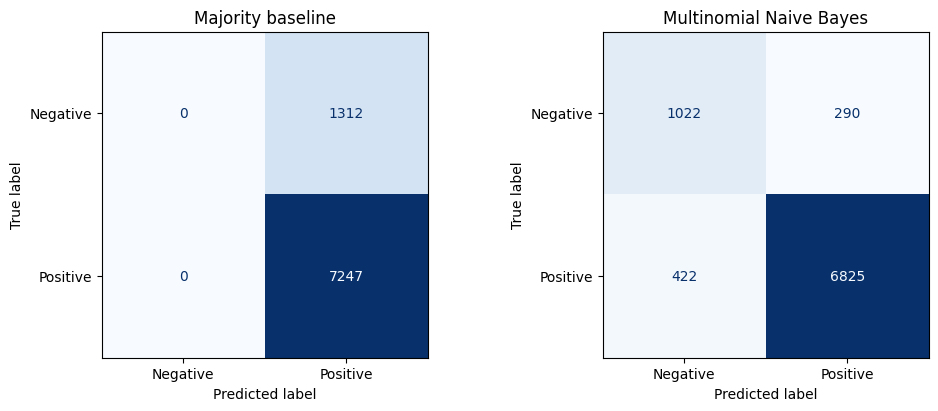

In [42]:
# Confusion matrices for the baseline and Naive Bayes.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        labels=[0, 1],
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

fig.savefig("milestone2_confusion_matrices.png", dpi=200)
plt.show()